# NB2 - Baselines B1, B2, B3 (GeoGraphNet)

**Run on:** GPU (T4 or P100), **Internet: ON** (pretrained weights are downloaded; without Internet the notebook falls back to training from scratch and says so).
**Input to add:** the Kaggle Dataset made from the NB1 output (`X16_float16.npy`, `folds.csv`, `labels.npy`, `channel_stats.json`).

| Exp | Model | Input | Question |
|---|---|---|---|
| B1 | EfficientNetV2-S | RGB (B4, B3, B2) | standard 3-channel ceiling |
| B2 | EfficientNetV2-S | 16 channels (13 bands + NDVI, NDWI, NDBI) | value of multispectral + indices for a pure CNN |
| B3 | Swin-Tiny | 16 channels | does a rigid-patch transformer match the CNN? |

**Alignment with the workflow**
- Phase 1 split from NB1: train = folds 2-4, validation = fold 1, test = fold 0. The test fold is used once, after the best checkpoint is chosen on validation Macro-F1.
- Normalisation uses training-fold statistics only (`channel_stats.json`).
- One identical training recipe for all baselines and for the later A-series (NB4/NB5): AdamW, lr 3e-4, weight decay 1e-4, cosine annealing, label smoothing 0.1, same epochs, same seed. Edit `CFG` in Cell 1 once and keep it identical everywhere.
- Same backbone as the hybrid model (EfficientNetV2-S) so that B2 versus A1-A5 is a controlled comparison.
- Metrics: Accuracy, Macro-F1, Cohen's kappa, ECE, GFLOPs, latency (ms per patch, GPU, batch 128, data loading excluded).
- Hard-class-pair error audit (Annual/Permanent Crop, Residential/Industrial, Herbaceous Vegetation/Pasture, River/Highway).
- Optional Phase 2 (`RUN_CV = True` in Cell 1): the same code over all 5 folds for the final cross-validation (heavy: 5 folds x 3 models).

**Decisions to confirm with the team** (they are in `CFG`): input size (`img_size`, default 64 = native; the hybrid model in NB4 must use the same), number of epochs (default 30).

**Outputs (/kaggle/working):** checkpoints `best_B*.pt`, `nb2_baseline_metrics.csv`, `nb2_per_class_f1.csv`, `nb2_class_pair_errors.csv`, `nb2_history.csv`, `nb2_probs.npz` (validation and test probabilities), `nb2_confusion_matrices.png`, `nb2_training_curves.png`, `nb2_config.json`.

## Cell 1 - Configuration, seeding, GPU check, locate and load the NB1 data

In [1]:
import os, glob, json, time, random, subprocess, sys
import numpy as np, pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
try:
    import timm
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm"], check=True)
    import timm

# ---------------- one recipe for ALL experiments (keep identical in NB4/NB5) ----------------
CFG = dict(seed=42, epochs=30, batch_size=128, lr=3e-4, weight_decay=1e-4, label_smoothing=0.1,
           drop_rate=0.2, img_size=64, swin_window=4, num_workers=2,
           backbone_cnn="tf_efficientnetv2_s.in21k_ft_in1k", backbone_vit="swin_tiny_patch4_window7_224")
RUN_CV = False          # True: also run the 5-fold cross-validation (Cell 7); heavy
WORK = "/kaggle/working"
os.makedirs(WORK, exist_ok=True)

def seed_all(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_all(CFG["seed"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None",
      "| torch", torch.__version__, "| timm", timm.__version__)
if DEVICE.type != "cuda":
    print("WARNING: no GPU found, training will be very slow. Set Accelerator to GPU.")

cand = sorted(glob.glob("/kaggle/input/**/X16_float16.npy", recursive=True) + glob.glob(f"{WORK}/**/X16_float16.npy", recursive=True))
assert cand, "X16_float16.npy not found: add the NB1 output dataset under Input"
if len(cand) > 1:
    print("WARNING: several X16_float16.npy found, using the first:", cand)
NB1_DIR = os.path.dirname(cand[0])
print("NB1_DIR =", NB1_DIR, "|", sorted(os.listdir(NB1_DIR)))

idx = pd.read_csv(f"{NB1_DIR}/folds.csv")
stats = json.load(open(f"{NB1_DIR}/channel_stats.json"))
y_all = np.load(f"{NB1_DIR}/labels.npy")
try:
    X16 = np.load(f"{NB1_DIR}/X16_float16.npy")                  # ~3.5 GB in RAM: much faster than a memmap
except MemoryError:
    X16 = np.load(f"{NB1_DIR}/X16_float16.npy", mmap_mode="r")
    print("loaded as memmap (not enough RAM)")

assert X16.shape == (len(idx), 16, 64, 64), X16.shape
assert (idx["label"].values == y_all).all(), "labels.npy and folds.csv disagree"
CLASSES = [idx.loc[idx["label"] == i, "class"].iloc[0] for i in range(10)]
print("X16:", X16.shape, X16.dtype, "| classes:", CLASSES)
print("Phase 1 split counts:", idx["phase1"].value_counts().to_dict())

Device: cuda | GPU: Tesla T4 | torch 2.11.0+cu130 | timm 1.0.30
NB1_DIR = /kaggle/input/datasets/sudeeptamandal/eurosat-geograph-nb1-v2 | ['X13_uint16.npy', 'X16_float16.npy', 'channel_stats.json', 'data_root.txt', 'eda_band_means.png', 'folds.csv', 'labels.npy', 'near_duplicates.csv']
X16: (27000, 16, 64, 64) float16 | classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Phase 1 split counts: {'train': 16200, 'val': 5400, 'test': 5400}


## Cell 2 - Splits, Dataset/DataLoaders, metrics (Acc, Macro-F1, Kappa, ECE) and class-pair audit

In [2]:
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             cohen_kappa_score, confusion_matrix)

FOLDS = idx["fold"].values

def make_split(mode="phase1", k=0):
    # phase1: test fold 0, val fold 1, train folds 2-4.  cv: test fold k, val fold (k+1)%5, train = the other three.
    if mode == "phase1":
        tr = np.where(np.isin(FOLDS, [2, 3, 4]))[0]; va = np.where(FOLDS == 1)[0]; te = np.where(FOLDS == 0)[0]
        st = stats["phase1_train_folds_2_3_4"]
        assert (idx["phase1"].values[tr] == "train").all() and (idx["phase1"].values[va] == "val").all() \
               and (idx["phase1"].values[te] == "test").all(), "split disagrees with folds.csv"
    else:
        te_f, va_f = k, (k + 1) % 5
        tr = np.where(~np.isin(FOLDS, [te_f, va_f]))[0]; va = np.where(FOLDS == va_f)[0]; te = np.where(FOLDS == te_f)[0]
        st = stats["cv_train_excluding_fold"][str(k)]          # statistics from folds other than the test fold
    assert len(set(tr) & set(te)) == 0 and len(set(va) & set(te)) == 0 and len(set(tr) & set(va)) == 0
    return dict(mode=mode, k=k, tr=tr, va=va, te=te,
                mu=np.array(st["mean"], np.float32), sd=np.array(st["std"], np.float32))

class EuroSATBaselineDataset(Dataset):
    def __init__(self, indices, channels, mu, sd, augment=False):
        self.indices = np.asarray(indices, dtype=np.int64)
        self.channels = list(channels)
        self.mu = mu[self.channels][:, None, None]
        self.sd = sd[self.channels][:, None, None]
        self.augment = augment

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        r = self.indices[i]
        x = np.array(X16[r, self.channels], dtype=np.float32)
        x = (x - self.mu) / (self.sd + 1e-6)
        if self.augment:                                          # 90-degree rotations and flips (no label change)
            k = random.randint(0, 3)
            if k: x = np.rot90(x, k, axes=(1, 2))
            if random.random() < 0.5: x = np.flip(x, axis=2)
            if random.random() < 0.5: x = np.flip(x, axis=1)
            x = np.ascontiguousarray(x)
        return torch.from_numpy(x), torch.tensor(y_all[r], dtype=torch.long)

def _winit(wid):
    s = (torch.initial_seed() + wid) % (2 ** 32)
    random.seed(s); np.random.seed(s)

def make_loaders(channels, split):
    bs, nw = CFG["batch_size"], CFG["num_workers"]
    g = torch.Generator(); g.manual_seed(CFG["seed"])
    kw = dict(num_workers=nw, pin_memory=True, worker_init_fn=_winit, persistent_workers=(nw > 0))
    mk = lambda ids, aug: EuroSATBaselineDataset(ids, channels, split["mu"], split["sd"], aug)
    tr = DataLoader(mk(split["tr"], True), batch_size=bs, shuffle=True, generator=g, drop_last=False, **kw)
    va = DataLoader(mk(split["va"], False), batch_size=bs * 2, shuffle=False, **kw)
    te = DataLoader(mk(split["te"], False), batch_size=bs * 2, shuffle=False, **kw)
    return tr, va, te

def compute_ece(probs, labels, n_bins=15):
    conf, pred = probs.max(axis=1), probs.argmax(axis=1)
    acc = (pred == labels).astype(np.float32)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for b0, b1 in zip(bins[:-1], bins[1:]):
        m = (conf > b0) & (conf <= b1)
        if m.any():
            ece += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return float(ece)

def evaluate_predictions(probs, labels):
    p = probs.argmax(axis=1)
    return {"Acc": round(accuracy_score(labels, p) * 100, 3),
            "Macro_P": round(precision_score(labels, p, average="macro", zero_division=0) * 100, 3),
            "Macro_R": round(recall_score(labels, p, average="macro", zero_division=0) * 100, 3),
            "Macro_F1": round(f1_score(labels, p, average="macro", zero_division=0) * 100, 3),
            "Kappa": round(cohen_kappa_score(labels, p), 4),
            "ECE": round(compute_ece(probs, labels), 4)}

PAIRS = [("AnnualCrop", "PermanentCrop"), ("Residential", "Industrial"),
         ("HerbaceousVegetation", "Pasture"), ("River", "Highway")]

def class_pair_errors(cm, classes):
    tot_err = int(cm.sum() - np.trace(cm))
    rows = []
    for a, b in PAIRS:
        i, j = classes.index(a), classes.index(b)
        t = int(cm[i, j] + cm[j, i])
        rows.append({"pair": f"{a} <-> {b}", "a_as_b": int(cm[i, j]), "b_as_a": int(cm[j, i]),
                     "total_confusions": t, "share_of_all_errors_pct": round(100.0 * t / max(tot_err, 1), 2)})
    return pd.DataFrame(rows)

SPLIT = make_split("phase1")
print({k: len(SPLIT[k]) for k in ("tr", "va", "te")}, "| split OK, no overlap")
print("DataLoader, metric and audit functions ready.")

{'tr': 16200, 'va': 5400, 'te': 5400} | split OK, no overlap
DataLoader, metric and audit functions ready.


## Cell 3 - Models, trainer, profiling

- Pretrained weights are used when they can be downloaded; the result row records `Pretrained`.
- For 16-channel input, timm repeats and rescales the pretrained RGB first-layer filters, so only the first layer is RGB-initialised (state this in the paper).
- `img_size` in `CFG` is applied to all models (inputs are resized on the GPU when it is not 64).
- Latency: pure forward pass on random data, batch 128, after warm-up (no data loading). GFLOPs count a multiply-add as 2 FLOPs.

In [3]:
MODEL_SPECS = {
    "B1": dict(name="EfficientNetV2-S (RGB)",    channels=[3, 2, 1],        arch="cnn", ckpt="best_B1_rgb_cnn.pt"),
    "B2": dict(name="EfficientNetV2-S (16-Ch)",  channels=list(range(16)),  arch="cnn", ckpt="best_B2_16ch_cnn.pt"),
    "B3": dict(name="Swin-Tiny (16-Ch)",         channels=list(range(16)),  arch="vit", ckpt="best_B3_16ch_vit.pt"),
}
IMG = CFG["img_size"]

def prep(x):
    return x if IMG == 64 else F.interpolate(x, size=(IMG, IMG), mode="bilinear", align_corners=False)

def create(name, **kw):
    try:
        return timm.create_model(name, pretrained=True, **kw), True
    except Exception as e:
        print(f"WARNING: pretrained weights unavailable ({type(e).__name__}) -> training from scratch. "
              f"Turn Internet ON for pretrained weights.")
        return timm.create_model(name, pretrained=False, **kw), False

def build_model(code):
    spec = MODEL_SPECS[code]; n_ch = len(spec["channels"])
    if spec["arch"] == "cnn":
        return create(CFG["backbone_cnn"], in_chans=n_ch, num_classes=10, drop_rate=CFG["drop_rate"])
    return create(CFG["backbone_vit"], in_chans=n_ch, num_classes=10, drop_rate=CFG["drop_rate"],
                  img_size=IMG, window_size=CFG["swin_window"])

def make_scaler(enabled):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)

@torch.no_grad()
def predict_loader(model, loader):
    model.eval()
    P, Y = [], []
    for x, y in loader:
        x = prep(x.to(DEVICE, non_blocking=True))
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE.type == "cuda")):
            logits = model(x)
        P.append(torch.softmax(logits.float(), dim=-1).cpu().numpy()); Y.append(y.numpy())
    return np.concatenate(P, 0), np.concatenate(Y, 0)

@torch.no_grad()
def profile_model(model, n_ch, bs=128, reps=10):
    model.eval()
    gflops = float("nan")
    try:
        from torch.utils.flop_counter import FlopCounterMode
        with FlopCounterMode(display=False) as fc:
            model(prep(torch.randn(1, n_ch, 64, 64, device=DEVICE)))
        gflops = fc.get_total_flops() / 1e9
    except Exception as e:
        print("FLOP counting unavailable:", type(e).__name__)
    x = prep(torch.randn(bs, n_ch, 64, 64, device=DEVICE))
    with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE.type == "cuda")):
        for _ in range(5): model(x)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        t = time.time()
        for _ in range(reps): model(x)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
    return gflops, (time.time() - t) * 1000.0 / (bs * reps)

def run_experiment(code, split, epochs=None, tag=""):
    epochs = epochs or CFG["epochs"]
    spec = MODEL_SPECS[code]; channels = spec["channels"]
    seed_all(CFG["seed"])
    tr_dl, va_dl, te_dl = make_loaders(channels, split)
    model, pretrained = build_model(code)
    model = model.to(DEVICE)
    params_m = sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6

    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-6)
    crit = nn.CrossEntropyLoss(label_smoothing=CFG["label_smoothing"])
    use_amp = DEVICE.type == "cuda"
    scaler = make_scaler(use_amp)

    ckpt = f"{WORK}/{spec['ckpt'].replace('.pt', tag + '.pt')}"
    best, best_ep, hist, t0 = -1.0, 0, [], time.time()
    for ep in range(1, epochs + 1):
        model.train(); tl = 0.0
        for x, y in tr_dl:
            x, y = prep(x.to(DEVICE, non_blocking=True)), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                loss = crit(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(y)
        sched.step()
        vp, vy = predict_loader(model, va_dl)
        vres = evaluate_predictions(vp, vy)
        hist.append({"epoch": ep, "train_loss": tl / len(tr_dl.dataset), "val_acc": vres["Acc"],
                     "val_macro_f1": vres["Macro_F1"], "val_ece": vres["ECE"]})
        if vres["Macro_F1"] > best:
            best, best_ep = vres["Macro_F1"], ep
            torch.save(model.state_dict(), ckpt)
        if ep == 1 or ep % 5 == 0 or ep == epochs:
            print(f"[{code}{tag}] Ep {ep:02d}/{epochs} | loss {tl/len(tr_dl.dataset):.4f} | "
                  f"val F1 {vres['Macro_F1']:.2f}% | best {best:.2f}% (ep {best_ep}) | {(time.time()-t0)/60:.1f} min")
    train_min = (time.time() - t0) / 60.0

    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    te_p, te_y = predict_loader(model, te_dl)                     # test fold used once, with the best checkpoint
    va_p, va_y = predict_loader(model, va_dl)
    res = evaluate_predictions(te_p, te_y)
    gflops, ms = profile_model(model, len(channels))
    res.update({"Exp": code, "Model": spec["name"], "Channels": len(channels), "Params_M": round(params_m, 2),
                "GFLOPs": round(gflops, 3), "Infer_ms": round(ms, 4), "Train_Min": round(train_min, 2),
                "Best_Epoch": best_ep, "Pretrained": pretrained})
    print(f"--> {code} {tag} TEST: Acc={res['Acc']}% | Macro-F1={res['Macro_F1']}% | Kappa={res['Kappa']} | ECE={res['ECE']}\n")
    del model, opt
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return res, te_p, te_y, va_p, va_y, pd.DataFrame(hist)

## Cell 4 - Train and evaluate B1, B2, B3 on the Phase 1 split

In [4]:
CODES = ["B1", "B2", "B3"]
results, probs, vprobs, hists = [], {}, {}, {}
for code in CODES:
    res, tp, ty, vp, vy, h = run_experiment(code, SPLIT)
    results.append(res); probs[code] = tp; vprobs[code] = vp; hists[code] = h
    y_te, y_va = ty, vy

np.savez_compressed(f"{WORK}/nb2_probs.npz", y_test=y_te, y_val=y_va,
                    **{f"test_{c}": probs[c] for c in CODES}, **{f"val_{c}": vprobs[c] for c in CODES})
pd.concat([h.assign(Exp=c) for c, h in hists.items()]).to_csv(f"{WORK}/nb2_history.csv", index=False)
print("saved nb2_probs.npz and nb2_history.csv")

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.5MB            

model.safetensors: downloading bytes:           |  0.00B            

[B1] Ep 01/30 | loss 2.4740 | val F1 89.89% | best 89.89% (ep 1) | 0.4 min
[B1] Ep 05/30 | loss 0.6267 | val F1 97.14% | best 97.14% (ep 5) | 1.9 min
[B1] Ep 10/30 | loss 0.5643 | val F1 98.02% | best 98.02% (ep 10) | 3.7 min
[B1] Ep 15/30 | loss 0.5408 | val F1 98.25% | best 98.25% (ep 15) | 5.5 min
[B1] Ep 20/30 | loss 0.5301 | val F1 98.26% | best 98.32% (ep 16) | 7.3 min
[B1] Ep 25/30 | loss 0.5241 | val F1 98.28% | best 98.38% (ep 24) | 9.1 min
[B1] Ep 30/30 | loss 0.5230 | val F1 98.26% | best 98.38% (ep 24) | 10.9 min
--> B1  TEST: Acc=98.556% | Macro-F1=98.485% | Kappa=0.9839 | ECE=0.0847

[B2] Ep 01/30 | loss 2.5405 | val F1 88.88% | best 88.88% (ep 1) | 0.4 min
[B2] Ep 05/30 | loss 0.6338 | val F1 96.01% | best 96.01% (ep 5) | 1.9 min
[B2] Ep 10/30 | loss 0.5674 | val F1 97.27% | best 97.27% (ep 10) | 3.7 min
[B2] Ep 15/30 | loss 0.5456 | val F1 97.75% | best 97.75% (ep 15) | 5.6 min
[B2] Ep 20/30 | loss 0.5317 | val F1 97.90% | best 97.92% (ep 17) | 7.4 min
[B2] Ep 25/30 | l

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/timm/layers/interpolate.py:47: UserWarning: torch.searchsorted(): input value tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous input value tensor if possible. This message will only appear once per program. (Triggered internally at /pytorch/aten/src/ATen/native/BucketizationUtils.h:32.)
  idx_right = torch.bucketize(x, p)
/usr/local/lib/python3.13/dist-packages/timm/layers/interpolate.py:65: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
  numerator += self.values[as_s] * \


[B3] Ep 01/30 | loss 0.8275 | val F1 95.57% | best 95.57% (ep 1) | 0.2 min
[B3] Ep 05/30 | loss 0.5594 | val F1 96.46% | best 97.36% (ep 4) | 1.1 min
[B3] Ep 10/30 | loss 0.5352 | val F1 97.49% | best 97.96% (ep 9) | 2.3 min
[B3] Ep 15/30 | loss 0.5167 | val F1 98.16% | best 98.35% (ep 13) | 3.4 min
[B3] Ep 20/30 | loss 0.5097 | val F1 98.65% | best 98.65% (ep 20) | 4.5 min
[B3] Ep 25/30 | loss 0.5031 | val F1 98.68% | best 98.76% (ep 24) | 5.7 min
[B3] Ep 30/30 | loss 0.5027 | val F1 98.72% | best 98.76% (ep 24) | 6.8 min
--> B3  TEST: Acc=98.944% | Macro-F1=98.887% | Kappa=0.9883 | ECE=0.0823

saved nb2_probs.npz and nb2_history.csv


## Cell 5 - Summary metric table and per-class F1

In [5]:
cols = ["Exp", "Model", "Channels", "Acc", "Macro_P", "Macro_R", "Macro_F1", "Kappa", "ECE",
        "Params_M", "GFLOPs", "Infer_ms", "Train_Min", "Best_Epoch", "Pretrained"]
df_metrics = pd.DataFrame(results)[cols]
df_metrics.to_csv(f"{WORK}/nb2_baseline_metrics.csv", index=False)
print("=== Overall test performance (Phase 1: fold 0, single seed) ===")
display(df_metrics)

per_cls = {c: np.round(f1_score(y_te, probs[c].argmax(1), average=None, labels=list(range(10))) * 100, 2) for c in CODES}
df_cls = pd.DataFrame(per_cls, index=CLASSES)
df_cls["Gain B2-B1"] = (df_cls["B2"] - df_cls["B1"]).round(2)
df_cls.to_csv(f"{WORK}/nb2_per_class_f1.csv")
print("\n=== Per-class F1 (%) ===")
display(df_cls)

=== Overall test performance (Phase 1: fold 0, single seed) ===


,Exp,Model,Channels,Acc,Macro_P,Macro_R,Macro_F1,Kappa,ECE,Params_M,GFLOPs,Infer_ms,Train_Min,Best_Epoch,Pretrained
0,B1,EfficientNetV2-S (RGB),3,98.556,98.481,98.490,98.485,0.9839,0.0847,20.19,0.472,0.3217,10.95,24,True
1,B2,EfficientNetV2-S (16-Ch),16,97.981,97.892,97.867,97.875,0.9775,0.0831,20.19,0.478,0.3290,11.12,23,True
2,B3,Swin-Tiny (16-Ch),16,98.944,98.888,98.888,98.887,0.9883,0.0823,27.53,0.728,0.1918,6.78,24,True



=== Per-class F1 (%) ===


,B1,B2,B3,Gain B2-B1
AnnualCrop,98.58,98.16,98.58,-0.42
Forest,99.50,99.00,99.59,-0.50
HerbaceousVegetation,97.83,96.19,98.49,-1.64
Highway,98.30,97.68,99.00,-0.62
Industrial,98.70,98.60,99.00,-0.10
Pasture,97.50,95.02,97.49,-2.48
PermanentCrop,96.71,96.24,98.10,-0.47
Residential,99.50,99.00,99.50,-0.50
River,98.39,99.00,99.20,0.61
SeaLake,99.83,99.83,99.92,0.00


## Cell 6 - Confusion matrices, hard class-pair audit, training curves

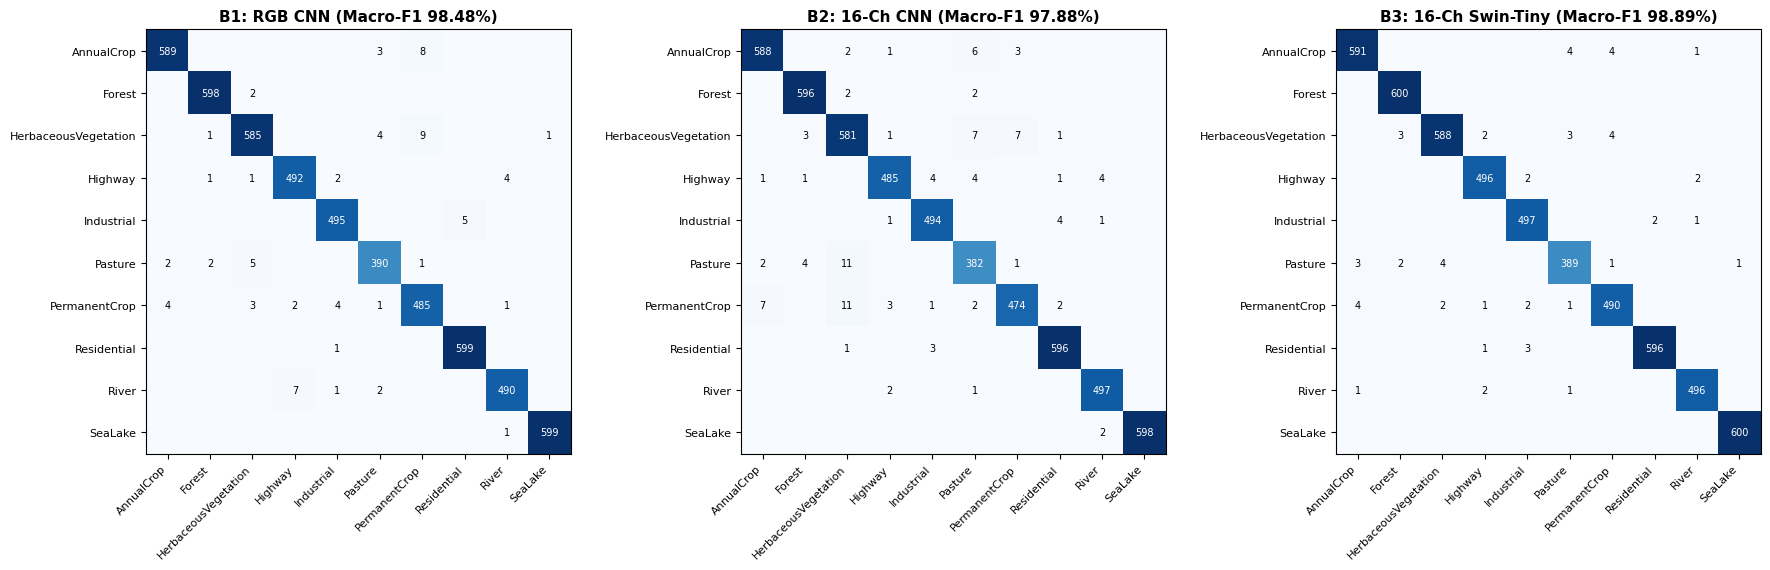

=== Hard class-pair confusions on the test fold (a_as_b: first class predicted as second) ===


,Exp,pair,a_as_b,b_as_a,total_confusions,share_of_all_errors_pct
0,B1,AnnualCrop <-> PermanentCrop,8,4,12,15.38
1,B1,Residential <-> Industrial,1,5,6,7.69
2,B1,HerbaceousVegetation <-> Pasture,4,5,9,11.54
3,B1,River <-> Highway,7,4,11,14.10
0,B2,AnnualCrop <-> PermanentCrop,3,7,10,9.17
1,B2,Residential <-> Industrial,3,4,7,6.42
2,B2,HerbaceousVegetation <-> Pasture,7,11,18,16.51
3,B2,River <-> Highway,2,4,6,5.50
0,B3,AnnualCrop <-> PermanentCrop,4,4,8,14.04
1,B3,Residential <-> Industrial,3,2,5,8.77


total test errors: {'B1': 78, 'B2': 109, 'B3': 57}


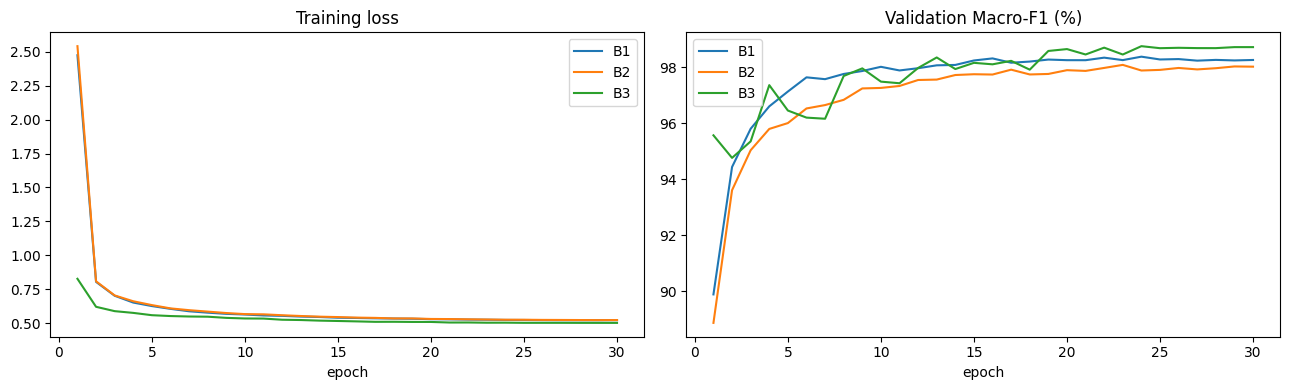

In [6]:
import matplotlib.pyplot as plt

cms = {c: confusion_matrix(y_te, probs[c].argmax(1), labels=list(range(10))) for c in CODES}
titles = {"B1": "B1: RGB CNN", "B2": "B2: 16-Ch CNN", "B3": "B3: 16-Ch Swin-Tiny"}
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))
for ax, c in zip(axes, CODES):
    cm = cms[c]; ax.imshow(cm, cmap="Blues")
    f1v = df_metrics.loc[df_metrics["Exp"] == c, "Macro_F1"].values[0]
    ax.set_title(f"{titles[c]} (Macro-F1 {f1v:.2f}%)", fontsize=11, fontweight="bold")
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set_xticklabels(CLASSES, rotation=45, ha="right", fontsize=8); ax.set_yticklabels(CLASSES, fontsize=8)
    for i in range(10):
        for j in range(10):
            if cm[i, j] > 0:
                ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=7,
                        color="white" if cm[i, j] > cm.max() * 0.5 else "black")
plt.tight_layout(); plt.savefig(f"{WORK}/nb2_confusion_matrices.png", dpi=150); plt.show()

audit = pd.concat([class_pair_errors(cms[c], CLASSES).assign(Exp=c) for c in CODES])
audit = audit[["Exp", "pair", "a_as_b", "b_as_a", "total_confusions", "share_of_all_errors_pct"]]
audit.to_csv(f"{WORK}/nb2_class_pair_errors.csv", index=False)
print("=== Hard class-pair confusions on the test fold (a_as_b: first class predicted as second) ===")
display(audit)
print("total test errors:", {c: int(cms[c].sum() - np.trace(cms[c])) for c in CODES})

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for c in CODES:
    ax[0].plot(hists[c]["epoch"], hists[c]["train_loss"], label=c)
    ax[1].plot(hists[c]["epoch"], hists[c]["val_macro_f1"], label=c)
ax[0].set_title("Training loss"); ax[1].set_title("Validation Macro-F1 (%)")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.savefig(f"{WORK}/nb2_training_curves.png", dpi=130); plt.show()

## Cell 7 - Optional Phase 2: 5-fold cross-validation (set `RUN_CV = True` in Cell 1)

Each fold k: test = fold k, validation = fold (k+1) mod 5, training = the other three; normalisation statistics from the folds other than k.
This is heavy (5 folds x 3 models x `epochs`). Run it after the whole project is finished, with the settings frozen in Phase 1.

In [7]:
if not RUN_CV:
    print("RUN_CV is False: skipping the 5-fold cross-validation.")
else:
    cv_rows, cv_probs = [], {}
    for k in range(5):
        sp = make_split("cv", k)
        for code in CODES:
            res, tp, ty, vp, vy, h = run_experiment(code, sp, tag=f"_f{k}")
            res["Fold"] = k; cv_rows.append(res)
            cv_probs[f"test_{code}_f{k}"] = tp; cv_probs[f"y_test_f{k}"] = ty
            pd.DataFrame(cv_rows).to_csv(f"{WORK}/nb2_cv_results.csv", index=False)      # saved after every run
    np.savez_compressed(f"{WORK}/nb2_cv_probs.npz", **cv_probs)
    cv = pd.DataFrame(cv_rows)
    summ = cv.groupby("Exp")[["Acc", "Macro_F1", "Kappa", "ECE"]].agg(["mean", "std"]).round(3)
    display(summ)

RUN_CV is False: skipping the 5-fold cross-validation.


## Cell 8 - Save the configuration and list the outputs

In [8]:
cfg_out = dict(CFG)
cfg_out.update({"channels": {c: MODEL_SPECS[c]["channels"] for c in CODES}, "phase1_split": "train folds 2-4, val fold 1, test fold 0",
                "normalisation": "channel_stats.json: phase1_train_folds_2_3_4",
                "torch": torch.__version__, "timm": timm.__version__, "pretrained": {r["Exp"]: bool(r["Pretrained"]) for r in results},
                "note": "keep these hyperparameters identical in NB4/NB5"})
json.dump(cfg_out, open(f"{WORK}/nb2_config.json", "w"), indent=2)

print("files in /kaggle/working:")
for f in sorted(os.listdir(WORK)):
    p = os.path.join(WORK, f)
    if os.path.isfile(p):
        print(f"  {f:34s} {os.path.getsize(p)/1e6:9.2f} MB")
print("\nNext: Save Version (Save & Run All), then create a Kaggle Dataset from the output. "
      "NB4 compares the hybrid model against these baselines using nb2_probs.npz and nb2_config.json.")

files in /kaggle/working:
  __notebook__.ipynb                      0.26 MB
  best_B1_rgb_cnn.pt                     81.66 MB
  best_B2_16ch_cnn.pt                    81.67 MB
  best_B3_16ch_vit.pt                   110.18 MB
  nb2_baseline_metrics.csv                0.00 MB
  nb2_class_pair_errors.csv               0.00 MB
  nb2_config.json                         0.00 MB
  nb2_confusion_matrices.png              0.12 MB
  nb2_history.csv                         0.00 MB
  nb2_per_class_f1.csv                    0.00 MB
  nb2_probs.npz                           1.13 MB
  nb2_training_curves.png                 0.07 MB

Next: Save Version (Save & Run All), then create a Kaggle Dataset from the output. NB4 compares the hybrid model against these baselines using nb2_probs.npz and nb2_config.json.
